<a href="https://colab.research.google.com/github/jeyohub/flutter_another_sample/blob/master/kmeans_it14_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
directory = "/content/drive/MyDrive/datasets/Live.csv"

dataset = pd.read_csv(directory)
dataset

,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
0,246675545449582_1649696485147474,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,NaN,NaN,NaN,NaN
1,246675545449582_1649426988507757,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,NaN,NaN,NaN,NaN
2,246675545449582_1648730588577397,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,NaN,NaN,NaN,NaN
3,246675545449582_1648576705259452,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,NaN,NaN,NaN,NaN
4,246675545449582_1645700502213739,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7045,1050855161656896_1061863470556065,photo,9/24/2016 2:58,89,0,0,89,0,0,0,0,0,NaN,NaN,NaN,NaN
7046,1050855161656896_1061334757275603,photo,9/23/2016 11:19,16,0,0,14,1,0,1,0,0,NaN,NaN,NaN,NaN
7047,1050855161656896_1060126464063099,photo,9/21/2016 23:03,2,0,0,1,1,0,0,0,0,NaN,NaN,NaN,NaN
7048,1050855161656896_1058663487542730,photo,9/20/2016 0:43,351,12,22,349,2,0,0,0,0,NaN,NaN,NaN,NaN


In [ ]:
dataset.shape

(7050, 16)

In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   object 
 1   status_type       7050 non-null   object 
 2   status_published  7050 non-null   object 
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), int64(9), object(3)
memory 

In [ ]:
dataset.isnull().sum()

,0
status_id,0
status_type,0
status_published,0
num_reactions,0
num_comments,0
num_shares,0
num_likes,0
num_loves,0
num_wows,0
num_hahas,0


In [ ]:
dataset.drop(['Column1', 'Column2', 'Column3', 'Column4'], axis=1, inplace=True)

In [ ]:
sum_dupli = dataset.duplicated().sum()
print(sum_dupli)


51


In [ ]:
dataset = dataset.drop_duplicates()

In [ ]:
dataset

,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,246675545449582_1649696485147474,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0
1,246675545449582_1649426988507757,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0
2,246675545449582_1648730588577397,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0
3,246675545449582_1648576705259452,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0
4,246675545449582_1645700502213739,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
7045,1050855161656896_1061863470556065,photo,9/24/2016 2:58,89,0,0,89,0,0,0,0,0
7046,1050855161656896_1061334757275603,photo,9/23/2016 11:19,16,0,0,14,1,0,1,0,0
7047,1050855161656896_1060126464063099,photo,9/21/2016 23:03,2,0,0,1,1,0,0,0,0
7048,1050855161656896_1058663487542730,photo,9/20/2016 0:43,351,12,22,349,2,0,0,0,0


In [ ]:
dataset['status_published'].unique()

array(['4/22/2018 6:00', '4/21/2018 22:45', '4/21/2018 6:17', ...,
       '9/21/2016 23:03', '9/20/2016 0:43', '9/10/2016 10:30'],
      shape=(6913,), dtype=object)

In [ ]:
dataset.drop(['status_id', 'status_published', 'status_type'], axis= 1, inplace=True)

/tmp/ipykernel_727/3749190084.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataset.drop(['status_id', 'status_published', 'status_type'], axis= 1, inplace=True)


In [ ]:
set_columns = dataset.columns

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_scaled = pd.DataFrame(scaler.fit_transform(dataset), columns=set_columns, index=dataset.index)

X_scaled.head()



,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,0.112314,0.024393,0.076519,0.091720,0.140030,0.010791,0.006369,0.019608,0.0
1,0.031847,0.000000,0.000000,0.031847,0.000000,0.000000,0.000000,0.000000,0.0
2,0.048195,0.011243,0.016647,0.043312,0.031963,0.003597,0.006369,0.000000,0.0
3,0.023567,0.000000,0.000000,0.023567,0.000000,0.000000,0.000000,0.000000,0.0
4,0.045223,0.000000,0.000000,0.043312,0.013699,0.000000,0.000000,0.000000,0.0


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

dataset = scaler.fit_transform(dataset)

dataset = pd.DataFrame(dataset, columns=[set_columns])

dataset.head()


,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,0.112314,0.024393,0.076519,0.091720,0.140030,0.010791,0.006369,0.019608,0.0
1,0.031847,0.000000,0.000000,0.031847,0.000000,0.000000,0.000000,0.000000,0.0
2,0.048195,0.011243,0.016647,0.043312,0.031963,0.003597,0.006369,0.000000,0.0
3,0.023567,0.000000,0.000000,0.023567,0.000000,0.000000,0.000000,0.000000,0.0
4,0.045223,0.000000,0.000000,0.043312,0.013699,0.000000,0.000000,0.000000,0.0


In [ ]:
# from scipy.sparse import random
models ={}
scores =[]

for k in range(1,10):
  model = KMeans(n_clusters=k, n_init = 20, random_state=42).fit(X_scaled)
  models[k] = model
  silhouette = (
      silhouette_score(
          X_scaled,
          model.labels_,
          sample_size=min(3000, len(X_scaled)),
          random_state=42
          )
          if k > 1
          else None
  )
  scores.append({"k":k, "inertia": model.inertia_, "silhouette": silhouette})

results = pd.DataFrame(scores).set_index("k")
best_k = int(results["silhouette"].idxmax())
best_score = results.loc[best_k, "silhouette"]

print(f"Best K: {best_k}, Silhouette Score: {best_score}")
display(results.round(3))


Best K: 3, Silhouette Score: 0.8226471497183969


,inertia,silhouette
k,,
1,195.517,NaN
2,95.992,0.817
3,72.746,0.823
4,58.927,0.640
5,48.150,0.699
6,42.838,0.616
7,37.956,0.634
8,34.411,0.632
9,31.740,0.636


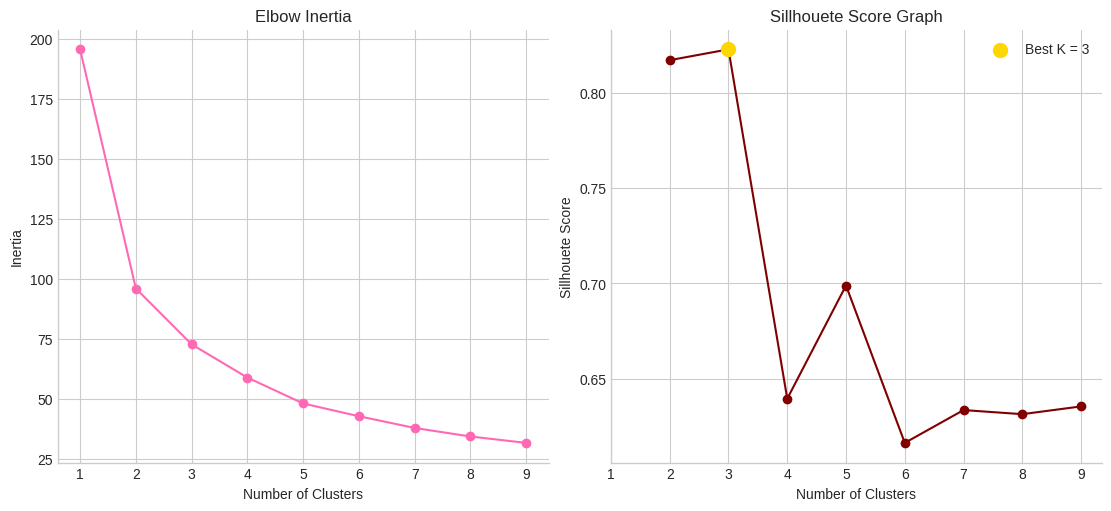

In [ ]:
plt.style.use("seaborn-v0_8-whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(11,5), layout="constrained")
axes[0].plot(results.index, results["inertia"], "o-", color="#FF69B4")
axes[0].set(title="Elbow Inertia", ylabel="Inertia")

sillhouete_val = results["silhouette"].dropna()
axes[1].scatter(
    best_k, best_score, color="#FFD700", s=100, zorder = 3, label=f"Best K = {best_k}"
)
axes[1].plot(
    sillhouete_val.index, sillhouete_val, "o-", color="#800000"
)

axes[1].set(title="Sillhouete Score Graph", ylabel="Sillhouete Score")
axes[1].legend(loc="best")

for ax in axes:
  ax.set(xlabel="Number of Clusters", xticks=results.index)
  ax.spines[["top", "right"]].set_visible(False)

plt.show()



In [ ]:
dataset_cluster = pd.read_csv(directory)

dataset_cluster = dataset_cluster.drop_duplicates()

dataset_cluster.drop(['Column1', 'Column2', 'Column3','Column4' ,'status_id', 'status_published', 'status_type'], axis= 1, inplace=True)

dataset_cluster



,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,529,512,262,432,92,3,1,1,0
1,150,0,0,150,0,0,0,0,0
2,227,236,57,204,21,1,1,0,0
3,111,0,0,111,0,0,0,0,0
4,213,0,0,204,9,0,0,0,0
...,...,...,...,...,...,...,...,...,...
7045,89,0,0,89,0,0,0,0,0
7046,16,0,0,14,1,0,1,0,0
7047,2,0,0,1,1,0,0,0,0
7048,351,12,22,349,2,0,0,0,0


In [ ]:
best_model = models[best_k]
dataset_cluster = dataset_cluster.assign(cluster=best_model.labels_)

groups = dataset_cluster.groupby("cluster")
cluster_sizes = groups.size().rename("Number of Posts")
cluster_profile = groups[["num_reactions", "num_shares", "num_likes", "num_comments"]].mean()
cluster_profile.columns = ["Average Reactions", "Average Shares", "Average Likes", "Average Comments"]
cluster_profile.insert(0, "Share (%)", cluster_sizes / cluster_sizes.sum() * 100)
cluster_profile.insert(0, "No. Posts", cluster_sizes)
display(cluster_profile.round(2))

,No. Posts,Share (%),Average Reactions,Average Shares,Average Likes,Average Comments
cluster,,,,,,
0,6454,92.21,113.17,26.58,103.54,150.78
1,171,2.44,1065.07,612.82,822.29,3416.57
2,374,5.34,1770.69,14.52,1766.16,56.86


In [ ]:
dataset_cluster.to_csv("WithCluster_Data.csv", index=False)